In [1]:
import io
from datasets import load_dataset
from tensorflow.image import resize as tf_resize
import numpy as np
import os, re, hashlib, io
from tqdm.auto import tqdm
from PIL import Image
import json
from tqdm.notebook import tqdm
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import textwrap
from sklearn.model_selection import GroupShuffleSplit
import matplotlib.patches as mpatches
import gc, torch, pandas as pd
import torch.nn.functional as F
from tqdm.auto import tqdm
import optuna
import subprocess, sys
from open_clip import create_model_from_pretrained, get_tokenizer
from sklearn.metrics import confusion_matrix
import seaborn as sns
import gc, torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoProcessor, AutoModel, get_cosine_schedule_with_warmup
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import math
import faiss

# Multimodal Medical Encoders: Classification & Retrieval

## Project Overview

This notebook demonstrates how to use **multimodal medical image encoders** for two distinct tasks on radiology data from the [OpenPMC dataset](https://huggingface.co/datasets/vector-institute/open-pmc):

| Task | Model | Objective |
|---|---|---|
| **Classification** | MedSigLIP (`google/medsiglip-448`) | Classify radiology images as X-ray vs CT |
| **Retrieval** | BiomedCLIP (`microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224`) | Given an image, retrieve the matching caption |

## Key Design Decisions

- **Official TF bilinear resizing** (`tf_resize` at 448×448, no antialias) - matches the Big Vision preprocessing pipeline MedSigLIP was trained with
- **MedSigLIP → Classification** with a small MLP head (1152→256→2) on frozen image embeddings; trained with a custom loop (no HuggingFace Trainer)
- **EmbeddingMemoryBank** (circular buffer of 256 past embeddings) for the BiomedCLIP retrieval task — massively increases negative pressure without touching batch size or VRAM
- **Gradient accumulation** (4 steps) and cosine LR schedule with warmup for stable BiomedCLIP training
- **Zero-shot vs fine-tuned** comparison for both tasks


In [2]:
dataset = load_dataset(
    "vector-institute/open-pmc",
    split="train",
    streaming=True
)
example = next(iter(dataset))
print(example.keys())

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

Resolving data files:   0%|          | 0/350 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/44 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/44 [00:00<?, ?it/s]

dict_keys(['jpg', 'jsonl', '__key__', '__url__'])


In [3]:
os.makedirs("data/images", exist_ok=True)


def resize_image(image):
    """
    Official MedSigLIP preprocessing: TF bilinear resize to 448×448.
    Matches the Big Vision implementation used during pre-training.
    Using standard PIL LANCZOS or cv2 resizing introduces subtle distribution
    mismatch that degrades both retrieval and classification performance
    """
    arr = np.array(image)
    resized = tf_resize(
        images=arr, size=[448, 448], method='bilinear', antialias=False
    ).numpy().astype(np.uint8)
    return Image.fromarray(resized)

In [4]:
ds_stream = load_dataset(
    "vector-institute/open-pmc",
    split="train",
    streaming=True
)

Resolving data files:   0%|          | 0/350 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/44 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/44 [00:00<?, ?it/s]

In [5]:
def get_meta(ex):
    j = ex["jsonl"]
    if isinstance(j, (bytes, bytearray)):
        j = j.decode("utf-8")
    return json.loads(j)

def get_modality(ex):
    meta = get_meta(ex)
    return (meta.get("modality") or "").strip()

def get_caption(ex):
    meta = get_meta(ex)
    sub = meta.get("sub_caption") or meta.get("Sub-caption") or ""
    full = meta.get("full_caption") or meta.get("Full caption") or meta.get("caption") or ""
    sub = sub.strip()
    full = full.strip()
    return sub if sub else full

def get_pmc_id(ex):
    meta = get_meta(ex)
    return meta.get("PMC_ID") or meta.get("pmc_id") or "NA"

def get_image(ex):
    jpg = ex["jpg"]
    if isinstance(jpg, (bytes, bytearray)):
        return Image.open(io.BytesIO(jpg)).convert("RGB")
    if hasattr(jpg, "convert"):
        return jpg.convert("RGB")
    return None

## Data Collection & Filtering Strategy

The [OpenPMC dataset](https://huggingface.co/datasets/vector-institute/open-pmc) is too large to download fully, so it is **streamed** and filtered in real time. Only records that pass all three conditions below are kept:

### Filtering Criteria

1. **Modality code `"R"` (radiology)** - each record's JSON metadata contains a `modality` field. only `"R"` records (radiology figures) are retained. This excludes pathology slides, charts, diagrams, etc.
2. **Non-empty caption** - `sub_caption` is preferred (more specific). falls back to `full_caption` or `caption`. Records with no usable text are skipped.
3. **Valid JPEG image** - the raw `jpg` bytes must open successfully as an RGB PIL image. Corrupt or missing images are skipped.

### Helper Functions

| Function | Purpose |
|---|---|
| `get_meta(ex)` | Decodes the raw JSON bytes from the `jsonl` field into a Python dict |
| `get_caption(ex)` | Extracts the best available caption (sub - full - caption) |
| `get_modality(ex)` | Reads the `modality` field from metadata |
| `get_pmc_id(ex)` | Reads the PMC article ID (used for grouping in the train/val/test split) |
| `get_image(ex)` | Decodes the JPEG bytes into a PIL RGB image |

### Submodality Labelling

Each kept record is tagged with one of three labels using regex on the caption text:
- **`xray`** - matches *x-ray, radiograph, CXR, plain film* (case-insensitive)
- **`ct`** - matches *CT, computed tomography*
- **`unknown`** - neither matched (includes MRI, ultrasound, PET, etc.)

### Target Sample Size
`TARGET_KEEP` (cell-8) controls how many records to collect.

In [6]:
XRAY_PAT = re.compile(r"\b(x[\s-]?ray|xray|radiograph|radiographic|plain\s*film|cxr)\b", re.I) # re.I ignores case
CT_PAT = re.compile(r"\b(ct|c\.t\.|computed\s*tomography)\b", re.I)

def label_xray_ct(caption):
    c = caption.lower()
    x = bool(XRAY_PAT.search(c))
    t = bool(CT_PAT.search(c))
    if x and not t: return "xray"
    if t and not x: return "ct"
    return "unknown"

In [7]:
TARGET_KEEP = 1000

In [9]:
rows = []
kept = 0
seen_captions = set()

scan_bar = tqdm(ds_stream, desc="Scanning")
keep_bar = tqdm(total=TARGET_KEEP, desc="Collected", position=1, leave=True)

for ex in scan_bar:
    if (get_modality(ex) or "").strip().upper() != "R":
        continue

    caption = get_caption(ex)
    img = get_image(ex)
    if not caption or img is None:
        continue

    # Deduplicate by caption text
    if caption in seen_captions:
        continue

    pmc_id = get_pmc_id(ex)
    submod = label_xray_ct(caption)

    # Keep only confirmed X-ray or CT samples
    if submod not in ["xray", "ct"]:
        continue

    h = hashlib.md5(f"{pmc_id}-{kept}".encode("utf-8")).hexdigest()[:12]
    img_path = f"data/images/{pmc_id}_{h}.png"

    # Apply official TF bilinear resize before saving
    img = img.convert("RGB")
    img = resize_image(img)
    img.save(img_path)

    rows.append({
        "PMC_ID": pmc_id,
        "image_path": img_path,
        "caption": caption,
        "rad_submodality": submod,
    })

    seen_captions.add(caption)
    kept += 1
    keep_bar.update(1)

    if kept >= TARGET_KEEP:
        break

keep_bar.close()

Scanning: 0it [00:00, ?it/s]

Collected:   0%|          | 0/1000 [00:00<?, ?it/s]

## Dataset Assembled

The streaming loop has finished. Each row in the resulting DataFrame represents one radiology figure and contains:

| Column | Type | Description |
|---|---|---|
| `PMC_ID` | str | PubMed Central article identifier (used as group key in the split) |
| `image_path` | str | Local path to the saved PNG file under `data/images/` |
| `caption` | str | Radiology figure caption (sub-caption preferred over full caption) |
| `rad_submodality` | str | `xray`, `ct`, or `unknown` |

The DataFrame is serialised to **`data/subset.parquet`** for reproducibility. Subsequent cells reload from this file, so the streaming loop only needs to run once.

In [10]:
df = pd.DataFrame(rows)
df.to_parquet("data/subset.parquet", index=False)

In [11]:
df

,PMC_ID,image_path,caption,rad_submodality
0,PMC11124728,data/images/PMC11124728_2c5387c9e27f.png,Chest CT of the patient in case 2 aged 10 yr a...,ct
1,PMC11088049,data/images/PMC11088049_cacab26c5315.png,Micro-CT with contrast medium scan from a diff...,ct
2,PMC9975129,data/images/PMC9975129_16e72fd59465.png,Postoperative panoramic radiograph after 2 yea...,xray
3,PMC11157359,data/images/PMC11157359_98708d3d764b.png,CT scan showing a right inguinoscrotal hernia ...,ct
4,PMC10784865,data/images/PMC10784865_3706374b4d47.png,CT with contrast medium of the abdomen showing...,ct
...,...,...,...,...
995,PMC11139841,data/images/PMC11139841_46d2bcd71e50.png,a–e Magnetic resonance (MR) images of a 63-yea...,ct
996,PMC9492350,data/images/PMC9492350_698959c550e6.png,Coronal section (left) and axial section (righ...,ct
997,PMC10464456,data/images/PMC10464456_f073861a5085.png,CT images of domestic ducks (ventrolateral vie...,ct
998,PMC11100271,data/images/PMC11100271_d2618ef4d003.png,Preoperative CT scan images (A) Coronal sectio...,ct


## Dataset Samples

Before training, it is useful to visually inspect what the collected data looks like.
The cells below display a grid of sample images with their captions and submodality
labels, and show the class distribution of the assembled dataset.


/tmp/ipykernel_752/2195623231.py:11: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(min(3, len(g)), random_state=42))


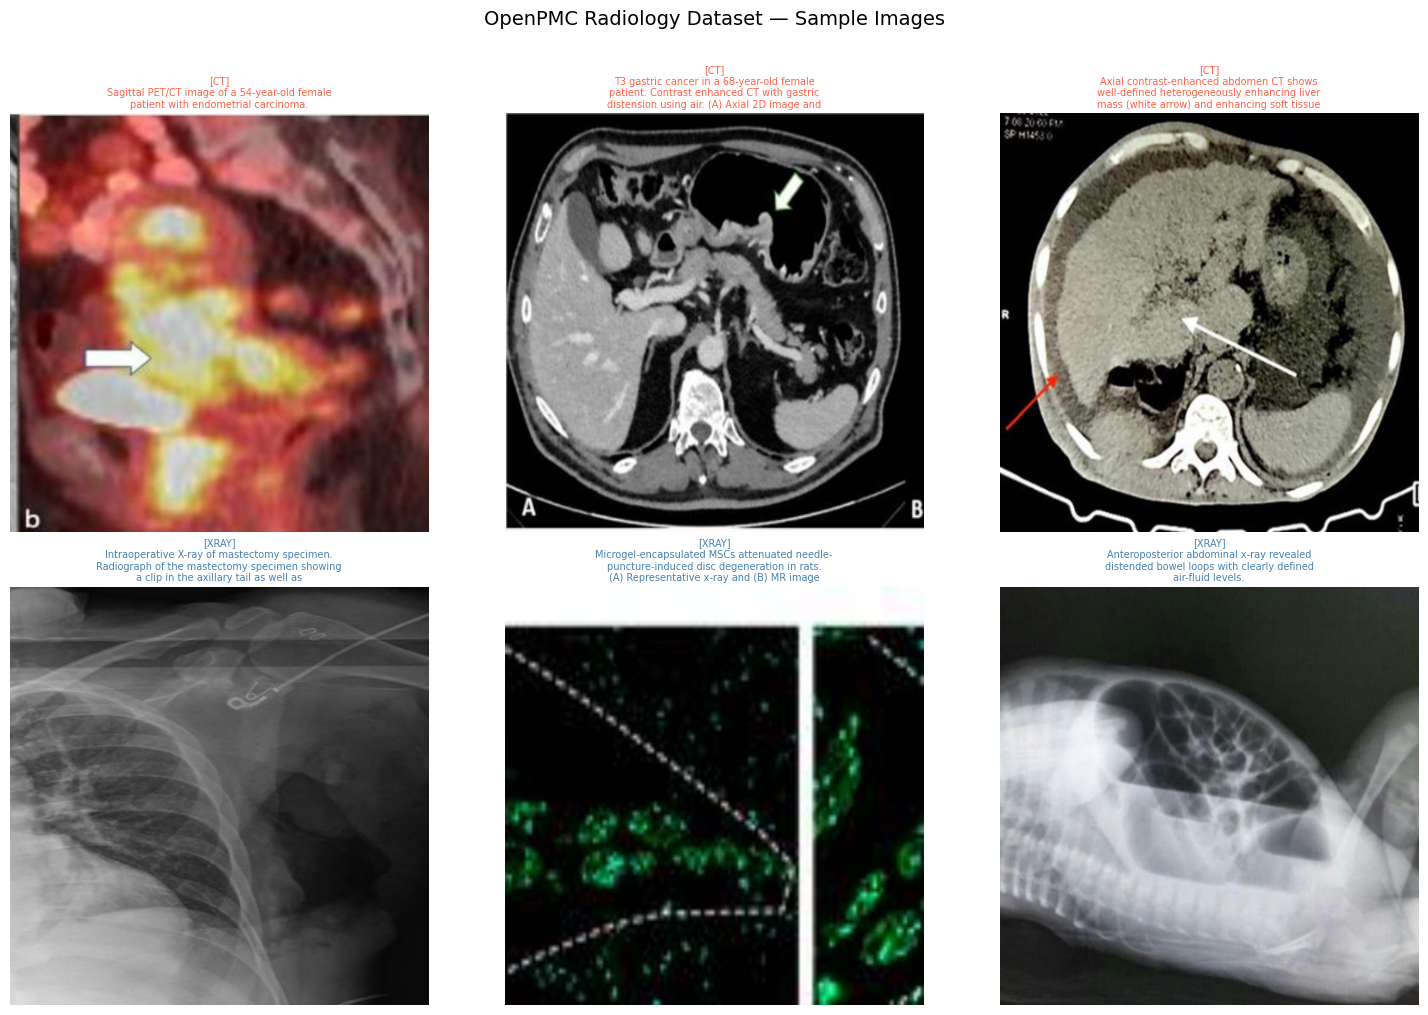

Class distribution in the full dataset:
          ct   787  ████████████████████████████████████████
        xray   213  ██████████

Caption length statistics (characters):
count    1000.000000
mean      325.922000
std       382.070595
min         9.000000
25%       101.000000
50%       186.000000
75%       415.000000
max      4656.000000


In [12]:
df_sample = (
    df.groupby("rad_submodality", group_keys=False)
      .apply(lambda g: g.sample(min(3, len(g)), random_state=42))
      .reset_index(drop=True)
)

n_cols = 3
n_rows = (len(df_sample) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 5))
axes = axes.flatten()

for i, (_, row) in enumerate(df_sample.iterrows()):
    ax = axes[i]
    try:
        img = Image.open(row["image_path"]).convert("RGB")
        ax.imshow(img, cmap="gray" if img.mode == "L" else None)
    except Exception:
        ax.text(0.5, 0.5, "[Image unavailable]", ha="center", va="center", fontsize=9)
    caption_short = "\n".join(textwrap.wrap(row["caption"][:130], width=45))
    label_color   = {"xray": "steelblue", "ct": "tomato", "unknown": "gray"}.get(
        row["rad_submodality"], "black"
    )
    ax.set_title(
        f"[{row['rad_submodality'].upper()}]\n{caption_short}",
        fontsize=7, pad=4, color=label_color
    )
    ax.axis("off")

for j in range(i + 1, len(axes)):
    axes[j].axis("off")

plt.suptitle("OpenPMC Radiology Dataset — Sample Images", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

# Class distribution
print("Class distribution in the full dataset:")
counts = df["rad_submodality"].value_counts()
for label, count in counts.items():
    bar = "█" * int(count / counts.max() * 40)
    print(f"  {label:>10s}  {count:4d}  {bar}")

# Caption length statistics
df["caption_len"] = df["caption"].str.len()
print(f"\nCaption length statistics (characters):")
print(df["caption_len"].describe().to_string())


## Train / Validation / Test Split

The dataset is divided into three non-overlapping splits using scikit-learn's `GroupShuffleSplit` with **`PMC_ID` as the grouping key**. This guarantees that all figures from the same article end up in the same partition, preventing data leakage, figures from the same paper share visual style and vocabulary, so mixing them across splits would artificially inflate performance.

### Split Ratios

| Split | Fraction | Purpose |
|---|---|---|
| **Train** | 80 % | Contrastive fine-tuning |
| **Validation** | 10 % | Monitored during training; Optuna objective |
| **Test** | 10 % | Final evaluation only — never seen during training or hyperparameter search |

A two-step split is used: first a 80/20 train/temp split, then the 20 % temp is halved into val and test. Splits are saved as separate parquet files and reloaded in the next cell.

In [13]:
df = pd.read_parquet("data/subset.parquet")

# Filter to radiography images BEFORE splitting
# The streaming loop already filters by JSONL modality="R", but some
# figures still slip through as plots, diagrams, or ambiguous images
# (rad_submodality == "unknown"). We keep only confirmed X-ray / CT
# samples so all splits share the same clean, on-topic distribution
df = df[df["rad_submodality"].isin(["xray", "ct"])].reset_index(drop=True)
print(f"Radiography-only subset: {len(df)} images  "
      f"(xray={len(df[df['rad_submodality']=='xray'])}, "
      f"ct={len(df[df['rad_submodality']=='ct'])})")

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, temp_idx = next(gss.split(df, groups=df["PMC_ID"]))

train_df = df.iloc[train_idx].reset_index(drop=True)
temp_df = df.iloc[temp_idx].reset_index(drop=True)

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
val_idx, test_idx = next(gss2.split(temp_df, groups=temp_df["PMC_ID"]))

val_df = temp_df.iloc[val_idx].reset_index(drop=True)
test_df = temp_df.iloc[test_idx].reset_index(drop=True)

train_df.to_parquet("data/train.parquet", index=False)
val_df.to_parquet("data/val.parquet", index=False)
test_df.to_parquet("data/test.parquet", index=False)

print(len(train_df), len(val_df), len(test_df))

Radiography-only subset: 1000 images  (xray=213, ct=787)
800 98 102


In [14]:
train_df = pd.read_parquet("data/train.parquet")
val_df = pd.read_parquet("data/val.parquet")
test_df = pd.read_parquet("data/test.parquet")

corpus_df = pd.concat([train_df, val_df], ignore_index=True)
corpus_texts = corpus_df["caption"].tolist()

test_paths = test_df["image_path"].tolist()
test_caps = test_df["caption"].tolist()

print("Corpus captions:", len(corpus_texts))
print("Test images:", len(test_paths))

Corpus captions: 898
Test images: 102


In [15]:
print(corpus_df.columns.tolist())

['PMC_ID', 'image_path', 'caption', 'rad_submodality']


## Environment: Authentication & GPU Setup

Before any models are loaded, two checks are performed:

### 1 · HuggingFace Authentication
`google/medsiglip-448` is a **gated model** that requires an accepted licence and a valid HF token. The `login()` call reads from the Colab **`HF_TOKEN` secret**.

### 2 · GPU Memory Inspection
Both models need a GPU:
- **MedSigLIP** (~3.5 GB weights, ViT-L/14 @ 448 px) — requires fp16 and frozen vision backbone to fit on a T4 (15 GB VRAM)
- **PubMedCLIP** (~600 MB) — fits comfortably in fp32 on the same T4

`gc.collect()` + `torch.cuda.empty_cache()` are called before each model load throughout the notebook to reclaim memory from previously freed models.

In [17]:
!pip -q install -U huggingface_hub

from huggingface_hub import login
login()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 616.3/616.3 kB 20.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 111.8 MB/s eta 0:00:00


In [18]:
gc.collect()
torch.cuda.empty_cache()
print(torch.cuda.memory_allocated()/1e9, "GB allocated")
print(torch.cuda.memory_reserved()/1e9, "GB reserved")

0.0 GB allocated
0.0 GB reserved


In [19]:
print(torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else None)

True Tesla T4


## Task 1 — MedSigLIP: Submodality Classification (X-ray vs CT)

### Model: `google/medsiglip-448`

MedSigLIP is a **SigLIP-based** (Sigmoid Loss for Language-Image Pre-Training) multimodal
model pre-trained on a large corpus of radiology image-caption pairs. We repurpose its
powerful vision encoder for a supervised **binary classification** task: distinguishing
X-ray from CT images.

#### Papers & Resources

- **SigLIP** - *"Sigmoid Loss for Language-Image Pre-Training"*, Zhai et al., ICCV 2023 - [arXiv:2303.15343](https://arxiv.org/abs/2303.15343)
- **MedSigLIP** - *"Advancing Multimodal Medical Capabilities of Gemini"*, Google DeepMind, 2024 - [arXiv:2405.03162](https://arxiv.org/abs/2405.03162)
- **Model card**: [google/medsiglip-448](https://huggingface.co/google/medsiglip-448)

#### Architecture

MedSigLIP follows the SigLIP architecture: a **ViT-L/14** vision encoder paired with a
text encoder, both projecting into a shared 1152-dimensional embedding space. The key
distinction from CLIP is the **sigmoid (per-pair binary) loss** instead of a row-wise
softmax contrastive loss.

![SigLIP Architecture](https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/transformers/model_doc/siglip_architecture.png)

In this project, the vision encoder is used as a frozen feature extractor and a lightweight
classification head is trained on top:

```
Input Image (448×448)
    ↓  ViT-L/14 Vision Encoder  [FROZEN]
    ↓  image_embeds (1152-dim, L2-normalised)
    ↓  MLP head  (1152 → 256 → 2, ReLU, Dropout 0.3)
    ↓  CrossEntropyLoss
```

#### SigLIP Training Loss

SigLIP replaces the row-wise softmax of CLIP with an element-wise **sigmoid binary
cross-entropy** applied independently to every image-text pair in the batch.
For a batch of $N$ matched pairs, the pairwise logit is:

$$z_{ij} = t \cdot \langle v_i,\, u_j \rangle + b$$

where $v_i$ and $u_j$ are L2-normalised image and text embeddings, $t = e^{\log\_scale}$

is a learnable temperature, and $b$ is a learnable bias. The per-pair loss is:

$$\ell_{ij} = \log\,\sigma\!\left(z_{ij}\cdot(2\,y_{ij}-1)\right), \qquad y_{ij} = \mathbb{1}[i=j]$$


And the total batch loss averages over all $N^2$ pairs:

$$\mathcal{L}_{\text{SigLIP }} = -\frac{1}{N^2}\sum_{i=1}^{N}\sum_{j=1}^{N}\ell_{ij}$$

**Key advantage over CLIP softmax loss**: each pair is treated independently, no
row/column normalisation, so the model does not require large batch sizes to have
sufficient negatives. This makes SigLIP more stable and sample-efficient at small batches.

#### Design Decisions (this project)

- **Vision backbone is frozen** - the pre-trained features are already domain-relevant
- **Custom training loop** - no HuggingFace Trainer; pure PyTorch for full control
- **Zero-shot baseline** uses text-similarity scoring: embed class descriptions and compare
  cosine similarity with image embeddings to predict the label


preprocessor_config.json:   0%|          | 0.00/360 [00:00<?, ?B/s]

The image processor of type `SiglipImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 


config.json:   0%|          | 0.00/879 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/809 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/798k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/455 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/3.51G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/888 [00:00<?, ?it/s]

True label : ct
Caption    : Chest CT of the patient in case 2 aged 10 yr and 1 mo....

Zero-shot sigmoid scores:
  0.0002                                  chest x-ray radiograph
  0.0001                                  computed tomography CT scan
  0.0001                                  MRI magnetic resonance imaging

Predicted: chest x-ray radiograph


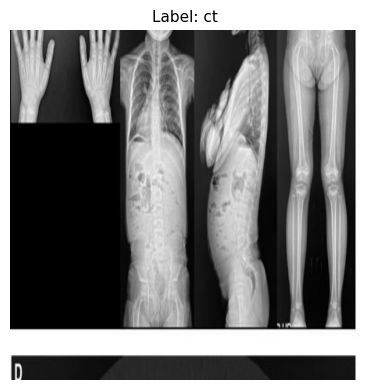

In [20]:
# MedSigLIP: Zero-Shot Quickstart (adapted from HuggingFace model card)
# Demonstrates standard zero-shot usage of MedSigLIP BEFORE any fine-tuning.
# Source: https://huggingface.co/google/medsiglip-448


# Load model and processor
processor_ms = AutoProcessor.from_pretrained("google/medsiglip-448")
model_ms = AutoModel.from_pretrained("google/medsiglip-448")
model_ms.eval()

# Pick a sample image from our collected dataset
sample_row = df.iloc[0]
image = Image.open(sample_row["image_path"]).convert("RGB")

# Candidate labels for zero-shot classification
candidate_labels = [
    "chest x-ray radiograph",
    "computed tomography CT scan",
    "MRI magnetic resonance imaging",
]

# Preprocessing
# MedSigLIP expects padding to max_length (important!)
inputs = processor_ms(
    text=candidate_labels,
    images=image,
    padding="max_length",
    return_tensors="pt",
)

# Forward pass
# SigLIP outputs raw logits — apply sigmoid (NOT softmax) to get probabilities
with torch.no_grad():
    outputs = model_ms(**inputs)

logits_per_image = outputs.logits_per_image # shape: [1, num_labels]
probs = torch.sigmoid(logits_per_image) # independent per-pair probabilities

# Results
print(f"True label: {sample_row['rad_submodality']}")
print(f"Caption: {sample_row['caption'][:80]}...\n")
print("Zero-shot sigmoid scores:")
for label, prob in zip(candidate_labels, probs[0]):
    bar = "█" * int(prob.item() * 30)
    print(f"  {prob:.4f}  {bar:30s}  {label}")

predicted = candidate_labels[probs[0].argmax().item()]
print(f"\nPredicted: {predicted}")

# Visualise the sample image
fig, ax = plt.subplots(1, 1, figsize=(4, 4))
ax.imshow(image)
ax.axis("off")
ax.set_title(f"Label: {sample_row['rad_submodality']}", fontsize=11)
plt.tight_layout()
plt.show()


In [21]:
# Model Exploration: MedSigLIP Architecture

device  = "cuda" if torch.cuda.is_available() else "cpu"
ms_name = "google/medsiglip-448"

ms_proc  = AutoProcessor.from_pretrained(ms_name)
ms_model = AutoModel.from_pretrained(ms_name, low_cpu_mem_usage=True).to(device)
ms_model.eval()

n_total = sum(p.numel() for p in ms_model.parameters())
# SiglipConfig does not expose projection_dim directly
# read it from the actual linear projection layer instead
proj_dim = ms_model.config.vision_config.hidden_size
print(f"Total parameters: {n_total:,}")
print(f"Projection dim (vision_config.hidden_size):       {proj_dim}")
print(f"Vision hidden dim: {ms_model.config.vision_config.hidden_size}")
print(f"Text hidden dim:   {ms_model.config.text_config.hidden_size}")


Loading weights:   0%|          | 0/888 [00:00<?, ?it/s]

Total parameters: 878,300,338
Projection dim (vision_config.hidden_size):       1152
Vision hidden dim: 1152
Text hidden dim:   1152


In [22]:
# Vision encoder parameters (will be frozen during classification fine-tuning)
n_vision = sum(p.numel() for p in ms_model.vision_model.parameters())
n_text = sum(p.numel() for p in ms_model.text_model.parameters())
proj_dim = ms_model.config.vision_config.hidden_size
print(f"Vision encoder: {n_vision:,} params")
print(f"Text encoder:   {n_text:,} params")
print(f"Classification head to add: {proj_dim} x 2 + 2 = {proj_dim * 2 + 2:,} params")


Vision encoder: 428,565,440 params
Text encoder:   449,734,896 params
Classification head to add: 1152 x 2 + 2 = 2,306 params


In [23]:
# If we were to fine-tune only the text encoder (retrieval task) these would be the trainable parameters
for p in ms_model.vision_model.parameters():
    p.requires_grad = False
n_train = sum(p.numel() for p in ms_model.parameters() if p.requires_grad)
print(f"Text encoder trainable params: {n_train:,}")
# Reset for classification experiments
import gc; del ms_model; gc.collect()
import torch; torch.cuda.empty_cache()
print("Model freed — fresh load will occur in the classification experiments cell.")


Text encoder trainable params: 449,734,898
Model freed — fresh load will occur in the classification experiments cell.


In [24]:
# Project scope:
# Task 1 — MedSigLIP: X-ray vs CT CLASSIFICATION
# Task 2 — BiomedCLIP: radiology caption RETRIEVAL

print("Task 1 — MedSigLIP  (google/medsiglip-448)")
print("            Architecture : ViT-L/14 @ 448 px (SigLIP)")
print("            Objective    : Binary classification (X-ray vs CT)")
print("            Head         : Linear(1152, 2), frozen vision backbone")
print()
print("Task 2 — BiomedCLIP (microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224)")
print("            Architecture : ViT-B/16 @ 224 px (CLIP/InfoNCE)")
print("            Objective    : Image-to-text retrieval (FAISS R@k, MRR)")
print("            Training     : CLIP loss + EmbeddingMemoryBank (256 negatives)")


Task 1 — MedSigLIP  (google/medsiglip-448)
            Architecture : ViT-L/14 @ 448 px (SigLIP)
            Objective    : Binary classification (X-ray vs CT)
            Head         : Linear(1152, 2), frozen vision backbone

Task 2 — BiomedCLIP (microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224)
            Architecture : ViT-B/16 @ 224 px (CLIP/InfoNCE)
            Objective    : Image-to-text retrieval (FAISS R@k, MRR)
            Training     : CLIP loss + EmbeddingMemoryBank (256 negatives)


In [25]:
# These helper functions confirm correct model types are loaded
def assert_medsiglip(model, proc):
    s = str(type(model)).lower()
    assert ("siglip" in s) or ("clip" in s), f"Not a SigLIP/CLIP-like model! Got: {s}"
    print(f"\u2713 MedSigLIP confirmed  ({type(model).__name__})")

def assert_biomedclip(model):
    s = str(type(model)).lower()
    # open_clip models have different class names
    assert hasattr(model, "encode_image"), "Not an open_clip model!"
    print(f"\u2713 BiomedCLIP confirmed ({type(model).__name__})")


## Retrieval Evaluation Metrics (Task 2 — BiomedCLIP)

BiomedCLIP is evaluated on the **image-to-text retrieval** task: given a query image,
rank all captions in the corpus by cosine similarity and measure how highly the correct
caption is ranked.

### Metrics Computed

| Metric | Intuition |
|---|---|
| **R@k** (k = 1, 5, 10) | Fraction of queries where the correct caption is in the top-k results. R@1 is strictest - the model must rank the correct caption first |
| **MRR** | Mean Reciprocal Rank - average of 1/rank for the correct caption |

Evaluation is run in **both directions**:
- **I2T** (image - text): given an image, retrieve the correct caption
- **T2I** (text - image): given a caption, retrieve the correct image

A FAISS `IndexFlatIP` (exact inner-product = cosine similarity on L2-normalised embeddings)
is used for efficient similarity search at this dataset scale.


In [26]:
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "faiss-cpu"], check=True)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'faiss-cpu'], returncode=0)

In [27]:
# Retrieval metrics

def recall_at_k(ranked, gt, k):
    return 1.0 if any(r in gt for r in ranked[:k]) else 0.0

def mrr(ranked, gt):
    for i, r in enumerate(ranked):
        if r in gt:
            return 1.0 / (i + 1)
    return 0.0


# FAISS helpers

def build_faiss_index(embs: np.ndarray) -> faiss.IndexFlatIP:
    """
    Build a flat inner-product index.
    Because embeddings are L2-normalised, IP = cosine similarity
    No approximation, exact search at this dataset scaole
    """
    d = embs.shape[1]
    index = faiss.IndexFlatIP(d)
    index.add(embs.astype(np.float32))
    return index


def _search(index, query_embs, corpus_items, query_gt_items, k_list=(1, 5, 10)):

    """
    Search FAISS index and compute R@k / MRR

    Parameters

    index: faiss.IndexFlatIP, built from corpus_items embeddings
    query_embs: np.ndarray (N_q, D) are L2-normalised query vectors
    corpus_items: list[str] are items in the FAISS index (captions or image paths)
    query_gt_items: list[str] is ground-truth item for each query
    """
    k_max = max(k_list)
    _, ranked = index.search(query_embs.astype(np.float32), k_max)

    item2idx = {}
    for j, c in enumerate(corpus_items):
        item2idx.setdefault(c, []).append(j)
    gt_sets = [set(item2idx.get(c, [])) for c in query_gt_items]

    totals = {f"R@{k}": 0.0 for k in k_list}
    total_mrr = 0.0
    n = len(query_gt_items)

    for i, hits in enumerate(ranked):
        gt = gt_sets[i]
        for k in k_list:
            if any(h in gt for h in hits[:k]):
                totals[f"R@{k}"] += 1.0
        for rank, h in enumerate(hits):
            if h in gt:
                total_mrr += 1.0 / (rank + 1)
                break

    metrics = {k: round(v / n, 4) for k, v in totals.items()}
    metrics["MRR"] = round(total_mrr / n, 4)
    return metrics


@torch.no_grad()
def evaluate_retrieval_faiss(embed_texts_fn, embed_images_fn,
                              query_df, corpus_texts,
                              batch_text=64, batch_img=16,
                              k_list=(1, 5, 10)):
    """
    Evaluate retrieval in BOTH directions using a FAISS flat IP index
    Image - Text (I2T): query with image embeddings, retrieve from text corpus
    Text - Image (T2I): query with text  embeddings, retrieve from image corpus
    Returns a dict with keys 'I2T' and 'T2I', each a dict of {R@k, MRR}
    """
    query_caps  = query_df["caption"].tolist()
    query_paths = query_df["image_path"].tolist()

    # Embed
    text_embs = embed_texts_fn(corpus_texts, batch_size=batch_text)
    img_embs = embed_images_fn(query_paths, batch_size=batch_img)

    if isinstance(text_embs, torch.Tensor):
        text_embs = text_embs.float().numpy()
    if isinstance(img_embs, torch.Tensor):
        img_embs = img_embs.float().numpy()

    text_embs = text_embs.astype(np.float32)
    img_embs = img_embs.astype(np.float32)

    # Image - Text (I2T)
    text_index = build_faiss_index(text_embs)
    i2t = _search(text_index, img_embs, corpus_texts, query_caps, k_list)

    # Text - Image (T2I): build image index from all train+val+test images
    # For T2I we treat each unique caption in the corpus as a query. the matching
    # image path is the ground truth.  We only evaluate on the query split here
    query_text_embs = embed_texts_fn(query_caps, batch_size=batch_text)
    if isinstance(query_text_embs, torch.Tensor):
        query_text_embs = query_text_embs.float().numpy()
    query_text_embs = query_text_embs.astype(np.float32)

    img_index = build_faiss_index(img_embs)
    # For T2I: corpus is the query images. ground truth = index position of the matching image
    img_paths_list = query_paths  # the indexed "corpus" for T2I is the query image set
    t2i = _search(img_index, query_text_embs, img_paths_list, img_paths_list, k_list)

    return {"I2T": i2t, "T2I": t2i}


# Keep backwards-compatible wrapper
@torch.no_grad()
def evaluate_retrieval(embed_texts_fn, embed_images_fn, query_df, corpus_texts,
                       batch_text=64, batch_img=16, k_list=(1, 5, 10), ndcg_k=10):
    out = evaluate_retrieval_faiss(embed_texts_fn, embed_images_fn, query_df, corpus_texts,
                                   batch_text, batch_img, k_list)
    return out["I2T"]

## Loss Functions & Memory Bank

### EmbeddingMemoryBank

With `batch_size = 8`, a standard contrastive loss only sees **7 negatives** per step.
The `EmbeddingMemoryBank` is a **circular buffer** that stores the last 256 past embeddings
from previous batches, providing up to **256 additional negatives** without any VRAM overhead.

Key properties:
- Stored embeddings are *detached* hence no gradient graph leak
- Oldest embeddings are naturally evicted as new ones arrive (FIFO)
- "Staleness" is negligible at learning rates ≤ 1e-5 — the encoder changes slowly enough
  that embeddings from 256 steps ago remain a useful negative signal

### `clip_loss` (InfoNCE, softmax)

Used for **BiomedCLIP retrieval**. Symmetric cross-entropy over the N×N similarity matrix.
Memory bank entries are appended as extra negative columns expanding the softmax denominatuor

### `siglip_loss` (sigmoid, binary cross-entropy)

Available as an alternative. Treats each (image, text) pair independently.
Must use `model.logit_scale.exp()`


In [28]:
# Memory Bank

class EmbeddingMemoryBank:
    """
    Circular buffer of past embeddings used to provide additional negatives
    for the contrastive loss without increasing the batch size or VRAM usage.

    With batch_size=8 there are only 7 in-batch negatives per step.
    By storing the last `size` embeddings we supply up to 256 extra negatives
    dramatically reducing the risk of representation collapse.

    Because embeddings are updated slowly (lr=5e-7 for MedSigLIP, 1e-5 for CLIP)
    the stored vectors remain compatible with the current encoder throughout
    training (‟staleness" is negligible at these learning rates)
    """
    def __init__(self, size: int, dim: int, device):
        self.size = size
        self.dim = dim
        self.device = device
        self.ptr = 0
        self.is_full = False
        self.images = torch.zeros(size, dim).to(device)
        self.texts = torch.zeros(size, dim).to(device)

    @torch.no_grad()
    def add(self, img_embs: torch.Tensor, txt_embs: torch.Tensor):
        bs = img_embs.shape[0]
        if self.ptr + bs > self.size:
            self.ptr     = 0
            self.is_full = True
        self.images[self.ptr : self.ptr + bs] = img_embs.detach()
        self.texts[self.ptr : self.ptr + bs] = txt_embs.detach()
        self.ptr = (self.ptr + bs) % self.size

    def get_all(self):
        if not self.is_full and self.ptr == 0:
            return None, None
        end = self.size if self.is_full else self.ptr
        return self.images[:end], self.texts[:end]


def similarity_stats(img_emb: torch.Tensor, txt_emb: torch.Tensor):
    """
    Return (mean_positive_sim, mean_negative_sim) for a batch.
    Positive pairs are on the diagonal. negatives are all off-diagonal.
    Inputs are L2-normalised (dot product = cosine similarity).
    """
    n = img_emb.size(0)
    sim = img_emb @ txt_emb.T
    pos_sim = sim.diagonal().mean().item()
    neg_mask = ~torch.eye(n, dtype=torch.bool, device=sim.device)
    neg_sim = sim[neg_mask].mean().item()
    return pos_sim, neg_sim


# Loss functions

def clip_loss(image_emb, text_emb, tau=0.07, memory_bank=None):
    """
    Symmetric InfoNCE / CLIP contrastive loss (softmax-based) with optional
    Memory Bank integration to expand the effective number of negatives.

    Without memory bank: N - 1 negatives per step
    With memory bank: N - 1 + M negatives (M = bank occupancy up to 256)
    """
    logits_i2t = image_emb @ text_emb.T / tau
    logits_t2i = logits_i2t.T

    if memory_bank is not None:
        mem_img, mem_txt = memory_bank.get_all()
        if mem_img is not None:
            # Expand denominator with stored past embeddings
            mem_logits_i = image_emb @ mem_txt.T / tau
            mem_logits_t = text_emb  @ mem_img.T / tau
            logits_i2t = torch.cat([logits_i2t, mem_logits_i], dim=1)
            logits_t2i = torch.cat([logits_t2i, mem_logits_t], dim=1)

    targets = torch.arange(image_emb.size(0), device=image_emb.device)
    loss_i2t = F.cross_entropy(logits_i2t, targets)
    loss_t2i = F.cross_entropy(logits_t2i, targets)
    return (loss_i2t + loss_t2i) / 2


def siglip_loss(image_emb, text_emb, model=None, memory_bank=None):

    if model is not None and hasattr(model, "logit_scale"):
        t = model.logit_scale.exp()
        b = model.logit_bias if hasattr(model, "logit_bias") else torch.zeros(1, device=image_emb.device)
    else:
        t = torch.tensor(10.0, device=image_emb.device)
        b = torch.tensor(-10.0, device=image_emb.device)

    logits = image_emb @ text_emb.T * t + b
    labels = torch.eye(logits.size(0), device=logits.device, dtype=image_emb.dtype)
    loss = F.binary_cross_entropy_with_logits(logits, labels)

    if memory_bank is not None:
        mem_img, mem_txt = memory_bank.get_all()
        if mem_img is not None:
            l_mt = image_emb @ mem_txt.T * t + b
            l_mi = text_emb  @ mem_img.T * t + b
            loss_mem = (F.binary_cross_entropy_with_logits(l_mt, torch.zeros_like(l_mt)) + F.binary_cross_entropy_with_logits(l_mi, torch.zeros_like(l_mi))) / 2
            loss = (loss + loss_mem) / 2

    return loss


In [29]:
# Triplet loss is kept for reference but is not used in the current experiments
# Both tasks use the losses defined above

def triplet_loss(image_emb, text_emb, margin=0.2):
    """
    Multi-negative in-batch triplet loss.
    Not used in the final experiments; kept as a reference implementation.
    """
    n = image_emb.size(0)
    pos = (image_emb * text_emb).sum(dim=1, keepdim=True)
    all_sim = image_emb @ text_emb.T
    eye = torch.eye(n, dtype=torch.bool, device=image_emb.device)
    neg_sim = all_sim.masked_fill(eye, -1e4)
    loss = torch.clamp(margin + neg_sim - pos, min=0)
    loss = loss.masked_fill(eye, 0)
    return loss.sum() / (n * (n - 1))


## Training Infrastructure

### Contrastive retrieval: `train_contrastive` (BiomedCLIP)

| Feature | Detail |
|---|---|
| **Gradient accumulation** | 4 steps - effective batch = 8 × 4 = 32 |
| **Memory Bank** | Circular buffer of 256 past embeddings passed to each loss call |
| **Positive/negative logging** | `similarity_stats()` logs the gap each step |
| **Cosine LR + warmup** | Prevents instability from large early gradients |
| **Best-checkpoint restoration** | Val MRR monitored; best weights restored after training |

### Classification: `train_classifier` (MedSigLIP)

| Feature | Detail |
|---|---|
| **Custom loop** | Pure PyTorch - no HuggingFace Trainer |
| **Frozen backbone** | Only the MLP head (1152→256→2, 295,682 parameters) is optimised |
| **Cross-entropy loss** | Standard supervised classification objective |
| **Cosine LR + warmup** | Same schedule as contrastive loop for consistency |


In [31]:
# Dataset

class PairDataset(Dataset):
    def __init__(self, df):
        self.paths = df["image_path"].tolist()
        self.caps = df["caption"].tolist()

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        cap = self.caps[i]
        if cap is None or (isinstance(cap, float) and math.isnan(cap)):
            cap = ""
        return self.paths[i], str(cap)

def _l2norm(x):
    return F.normalize(x, dim=-1)


# Forward functions (return L2-normalised image_emb, text_emb)

def forward_batch_biomedclip(model_tuple, paths, caps, device, max_length=256):
    """
    Forward pass for BiomedCLIP (open_clip).
    Returns (img_emb, txt_emb) — both L2-normalised.
    """
    clip_model, preprocess, tokenizer = model_tuple
    imgs = torch.stack([preprocess(Image.open(p).convert("RGB")) for p in paths]).to(device)
    toks = tokenizer(list(caps), context_length=max_length).to(device)
    img_emb = _l2norm(clip_model.encode_image(imgs))
    txt_emb = _l2norm(clip_model.encode_text(toks))
    return img_emb, txt_emb


# Embedding functions (evaluation time)

@torch.no_grad()
def embed_texts_generic(texts, processor, model, batch_size=64, max_length=None):
    """Embed a list of texts. Handles HF or open_clip (tuple) processors."""
    if isinstance(processor, tuple):
        preprocess, tokenizer = processor
        device = next(model.parameters()).device
        model.eval()
        all_embs = []
        for i in tqdm(range(0, len(texts), batch_size), desc="Embedding captions", leave=False):
            batch = ["" if t is None else str(t) for t in texts[i:i+batch_size]]
            toks = tokenizer(batch, context_length=256).to(device)
            emb = F.normalize(model.encode_text(toks), dim=-1)
            all_embs.append(emb.float().cpu())
        return torch.cat(all_embs, dim=0).numpy()

    if max_length is None:
        try: max_length = model.config.text_config.max_position_embeddings
        except: max_length = 64
    device = next(model.parameters()).device
    model.eval()
    embs = []
    for i in tqdm(range(0, len(texts), batch_size), desc="Embedding captions", leave=False):
        batch = ["" if t is None else str(t) for t in texts[i:i+batch_size]]
        inputs = processor(text=batch, return_tensors="pt",
                           padding=True, truncation=True, max_length=max_length)
        inputs = {k: v.to(device) for k, v in inputs.items() if v is not None}
        try:
            txt = model.get_text_features(input_ids=inputs["input_ids"],
                                          attention_mask=inputs.get("attention_mask"))
        except Exception:
            t_out = model.text_model(input_ids=inputs["input_ids"],
                                     attention_mask=inputs.get("attention_mask"))
            txt = getattr(t_out, "pooler_output",
                    getattr(t_out, "text_embeds", t_out.last_hidden_state[:, 0]))
            if hasattr(model, "text_projection"):
                proj = model.text_projection
                if txt.shape[-1] == proj.in_features:
                    txt = proj(txt)
        embs.append(_l2norm(txt).float().cpu())
    return torch.cat(embs, dim=0).numpy()


@torch.no_grad()
def embed_images_clip_like(paths, processor, model, batch_size=16):
    """Embed a list of image paths. Handles HF or open_clip (tuple) processors."""
    if isinstance(processor, tuple):
        preprocess, tokenizer = processor
        device = next(model.parameters()).device
        model.eval()
        all_embs = []
        for i in tqdm(range(0, len(paths), batch_size), desc="Embedding images", leave=False):
            imgs = torch.stack([preprocess(Image.open(p).convert("RGB"))
                                for p in paths[i:i+batch_size]]).to(device)
            emb = F.normalize(model.encode_image(imgs), dim=-1)
            all_embs.append(emb.float().cpu())
        return torch.cat(all_embs, dim=0).numpy()

    device = next(model.parameters()).device
    model.eval()
    embs = []
    for i in tqdm(range(0, len(paths), batch_size), desc="Embedding images", leave=False):
        imgs = [Image.open(p).convert("RGB") for p in paths[i:i+batch_size]]
        inputs = processor(images=imgs, return_tensors="pt")
        pv = inputs["pixel_values"].to(device)
        try:
            img = model.get_image_features(pixel_values=pv)
        except Exception:
            v_out = model.vision_model(pixel_values=pv)
            img = getattr(v_out, "pooler_output",
                    getattr(v_out, "image_embeds", v_out.last_hidden_state[:, 0]))
            if hasattr(model, "visual_projection"):
                proj = model.visual_projection
                if img.shape[-1] == proj.in_features:
                    img = proj(img)
        embs.append(_l2norm(img).float().cpu())
    return torch.cat(embs, dim=0).numpy()


# Contrastive training loop with Memory Bank + Gradient Accumulation

def train_contrastive(model_name, model, processor, train_df, val_df, corpus_texts,
                      forward_batch_fn, loss_fn,
                      epochs=5, lr=5e-6, batch_size=8,
                      accumulation_steps=4,
                      eval_every=1, fp16=True,
                      weight_decay=0.01, warmup_ratio=0.1, max_grad_norm=1.0,
                      embed_text_fn=None, embed_image_fn=None,
                      memory_bank=None,
                      return_metrics=False):
    """
    Contrastive fine-tuning with:
      - Gradient accumulation (accumulation_steps) for larger effective batch size
      - Memory Bank integration for expanded negative pool
      - Cosine LR schedule with linear warmup
      - Positive / negative similarity logging every step
      - Best-val-MRR checkpoint restoration
    """
    import warnings, gc
    warnings.filterwarnings("ignore", message=".*lr_scheduler.step.*")
    from transformers import get_cosine_schedule_with_warmup as get_sched

    ds = PairDataset(train_df)
    dl = DataLoader(ds, batch_size=batch_size, shuffle=True,
                    num_workers=2, drop_last=True)

    total_steps = (len(dl) // accumulation_steps) * epochs
    warmup_steps = max(1, int(total_steps * warmup_ratio))

    opt = torch.optim.AdamW(
        (p for p in model.parameters() if p.requires_grad),
        lr=lr, weight_decay=weight_decay,
    )
    scheduler = get_sched(opt, num_warmup_steps=warmup_steps, num_training_steps=total_steps)

    scaler = torch.amp.GradScaler("cuda", enabled=(fp16 and torch.cuda.is_available()))

    best_val_mrr = 0.0
    best_state = None
    history = []
    global_step = 0

    HDR = f"{'step':>6}  {'epoch':>5}  {'loss':>8}  {'pos_sim':>8}  {'neg_sim':>8}  {'gap':>8}"
    SEP = "-" * len(HDR)

    for ep in range(1, epochs + 1):
        model.train()
        opt.zero_grad(set_to_none=True)
        accum_loss, steps_in_epoch = 0.0, 0

        print(f"\n{SEP}\nEpoch {ep}/{epochs}\n{HDR}\n{SEP}")

        for i, (paths, caps) in enumerate(tqdm(dl, desc=f"[{model_name}] epoch {ep}", leave=True)):
            with torch.amp.autocast("cuda", enabled=(fp16 and torch.cuda.is_available())):
                img_emb, txt_emb = forward_batch_fn(paths, caps)
                loss = loss_fn(img_emb, txt_emb, memory_bank=memory_bank)
                scaled = loss / accumulation_steps
            scaler.scale(scaled).backward()
            accum_loss += loss.item() / accumulation_steps

            if (i + 1) % accumulation_steps == 0:
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(
                    (p for p in model.parameters() if p.requires_grad), max_grad_norm)
                scaler.step(opt)
                scaler.update()
                scheduler.step()
                opt.zero_grad(set_to_none=True)

                # Update memory bank with detached embeddings
                if memory_bank is not None:
                    memory_bank.add(img_emb.detach(), txt_emb.detach())

                global_step += 1
                steps_in_epoch += 1

                with torch.no_grad():
                    pos_sim, neg_sim = similarity_stats(img_emb, txt_emb)

                lr_now = scheduler.get_last_lr()[0]
                print(f"{global_step:>6}  {ep:>5}  {accum_loss:>8.5f}  "
                      f"{pos_sim:>8.5f}  {neg_sim:>8.5f}  {pos_sim-neg_sim:>8.5f}")
                history.append({
                    "step": global_step, "epoch": ep,
                    "loss": round(accum_loss, 5),
                    "pos_sim": round(pos_sim, 5),
                    "neg_sim": round(neg_sim, 5),
                    "gap": round(pos_sim - neg_sim, 5),
                })
                accum_loss = 0.0

        if ep % eval_every == 0:
            model.eval()
            _txt_fn = (embed_text_fn if embed_text_fn is not None
                       else lambda t, bs=64: embed_texts_generic(t, processor, model, batch_size=bs))
            _img_fn = (embed_image_fn if embed_image_fn is not None
                       else lambda p, bs=16: embed_images_clip_like(p, processor, model, batch_size=bs))
            metrics = evaluate_retrieval(
                lambda t, batch_size=64: _txt_fn(t, bs=batch_size),
                lambda p, batch_size=16: _img_fn(p, bs=batch_size),
                query_df=val_df,
                corpus_texts=corpus_texts,)

            print(f"[{model_name}] val I2T: {metrics}")
            gc.collect(); torch.cuda.empty_cache()
            if metrics.get("MRR", 0) > best_val_mrr:
                best_val_mrr = metrics["MRR"]
                best_state = {k: v.detach().cpu().clone()
                                for k, v in model.state_dict().items()}

    if best_state is not None:
        model.load_state_dict(best_state)
        print(f"[{model_name}] Restored best checkpoint  (val MRR: {best_val_mrr:.4f})")
    else:
        print(f"[{model_name}] No improvement — returning final epoch weights")

    if return_metrics:
        return model, best_val_mrr, history
    return model, history


# Model preparation helpers

def prepare_biomedclip(name, device):
    """Load BiomedCLIP via open_clip."""
    from open_clip import create_model_from_pretrained, get_tokenizer
    model, preprocess = create_model_from_pretrained(name)
    tokenizer = get_tokenizer(name)
    model = model.to(device)
    # Freeze vision encoder. fine-tune text encoder only
    for n, p in model.named_parameters():
        p.requires_grad = "text" in n
    n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    n_total = sum(p.numel() for p in model.parameters())
    print(f"BiomedCLIP — trainable: {n_train:,} / {n_total:,}  (vision frozen)")
    return model, preprocess, tokenizer


## MedSigLIP Classification: Hyperparameters

The classification head is a small MLP: Linear(1152→256) → ReLU → Dropout(0.3) → Linear(256→2).
The vision backbone is effectively frozen, so only the head parameters (295,682 weights) are
updated - no Optuna search needed

| Hyperparameter | Value | Rationale |
|---|---|---|
| `lr` | 1e-3 | Large LR is appropriate for a freshly initialised head |
| `weight_decay` | 1e-4 | Light regularisation; the head is small |
| `epochs` | 10 | Fast convergence. head trains in a few epochs |
| `batch_size` | 16 | Larger batch is fine since no gradient accumulation needed |

## BiomedCLIP Retrieval: Hyperparameters

For BiomedCLIP, an **Optuna TPE search** runs over learning rate, weight decay, and
warmup ratio. The memory bank is fixed at 256 embeddings across all trials.

| Hyperparameter | Search range |
|---|---|
| `lr` | 1e-6 – 5e-5 (log) |
| `weight_decay` | 1e-5 – 1e-2 (log) |
| `warmup_ratio` | 0.0 – 0.3 |


In [33]:
# Install dependencies
subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                "optuna", "open_clip_torch", "faiss-cpu"], check=True)

# MedSigLIP classification hyperparameters (fixed, no Optuna needed)
cls_params = {
    "lr": 1e-3,
    "weight_decay": 1e-4,
    "epochs": 10,
    "batch_size": 16,
}
print("MedSigLIP classification params:", cls_params)
print("BiomedCLIP retrieval params → searched via Optuna in the BiomedCLIP cell.")


MedSigLIP classification params: {'lr': 0.001, 'weight_decay': 0.0001, 'epochs': 10, 'batch_size': 16}
BiomedCLIP retrieval params → searched via Optuna in the BiomedCLIP cell.


In [ ]:
# MedSigLIP CLASSIFICATION EXPERIMENTS
#
# Task: Binary classification of radiology images as X-ray (0) or CT (1)
# Model: google/medsiglip-448 - ViT-L/14 vision encoder + linear head
# Labels: rad_submodality column in the dataset (xray=0, ct=1)
#
# Two configurations:
# [0] Zero-shot: text-similarity scoring with class descriptions, no training
# [1] Fine-tuned: custom training loop, cross-entropy loss, AdamW + cosine LR

device = "cuda" if torch.cuda.is_available() else "cpu"
ms_name = "google/medsiglip-448"

LABEL2ID = {"xray": 0, "ct": 1}
ID2LABEL = {0: "X-ray", 1: "CT"}
NUM_CLASSES = 2


# Dataset for classification

class ClassificationDataset(Dataset):
    """
    Returns pre-processed pixel_values tensors and integer labels.
    Images were saved using TF bilinear resize, the HF processor rescales to
    448×448 again, this is a no-op on already-resized images, ensuring
    consistent preprocessing across data collection, training, and evaluation
    """
    def __init__(self, df, processor):
        self.paths = df["image_path"].tolist()
        self.labels = [LABEL2ID[s] for s in df["rad_submodality"].tolist()]
        self.processor = processor

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert("RGB")
        inputs = self.processor(images=img, return_tensors="pt")
        return inputs["pixel_values"].squeeze(0), self.labels[idx]


# Classifier wrapper

class MedSigLIPClassifier(nn.Module):
    def __init__(self, base_model, num_classes: int = 2):
        super().__init__()
        self.base = base_model
        # Freeze entire backbone
        for p in self.base.vision_model.parameters():
            p.requires_grad = False
        # Unfreeze last 2 transformer layers
        for layer in self.base.vision_model.encoder.layers[-2:]:
            for p in layer.parameters():
                p.requires_grad = True
        proj_dim = base_model.config.vision_config.hidden_size  # 1152
        self.head = nn.Sequential(
            nn.Linear(proj_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

    def forward(self, pixel_values: torch.Tensor) -> torch.Tensor:
        # NO torch.no_grad() here, gradients must reach unfrozen layers
        img_emb = self.base.vision_model(pixel_values=pixel_values).pooler_output
        img_emb = F.normalize(img_emb, dim=-1)
        return self.head(img_emb)

classifier = MedSigLIPClassifier(ms_model, num_classes=NUM_CLASSES).to(device)
trainable = sum(p.numel() for p in classifier.parameters() if p.requires_grad)
print(f"Trainable: {trainable:,}")


# Zero-shot classification

@torch.no_grad()
def zero_shot_classify(model, processor, paths, device,
                        class_texts=("a chest x-ray radiograph",
                                     "a CT computed tomography scan"),
                        batch_size=16):
    """
    Zero-shot classification via cosine similarity between image embeddings
    and text embeddings of class descriptions.
    Returns predicted class indices (0 = x-ray, 1 = CT)
    """
    model.eval()

    # Encode class descriptions once
    txt_inputs = processor(
        text=list(class_texts),
        return_tensors="pt",
        padding="max_length",
        truncation=True,
        max_length=64,
    )
    txt_inputs = {k: v.to(device) for k, v in txt_inputs.items()}
    txt_embs = F.normalize(model.text_model(**txt_inputs).pooler_output, dim=-1)  # (C, D)

    all_preds = []
    for i in tqdm(range(0, len(paths), batch_size), desc="Zero-shot inference"):
        imgs = [Image.open(p).convert("RGB") for p in paths[i:i+batch_size]]
        inputs = processor(images=imgs, return_tensors="pt")
        pv = inputs["pixel_values"].to(device)
        img_embs = F.normalize(model.vision_model(pixel_values=pv).pooler_output, dim=-1)  # (B, D)
        sims = img_embs @ txt_embs.T   # (B, C)
        preds = sims.argmax(dim=-1).cpu().tolist()
        all_preds.extend(preds)

    return all_preds


# Custom training loop

def train_classifier(classifier, processor, train_df, val_df,
                     epochs=10, lr=1e-3, weight_decay=1e-4, batch_size=16):
    """
    Pure-PyTorch training loop for the linear classification head.
    Cosine LR schedule with linear warmup; early stopping on val accuracy.
    Only the head parameters are updated (vision encoder is frozen inside
    the MedSigLIPClassifier.forward)
    """
    train_ds = ClassificationDataset(train_df, processor)
    val_ds = ClassificationDataset(val_df,   processor)
    train_dl = DataLoader(train_ds, batch_size=batch_size, shuffle=True,
                          num_workers=2, drop_last=True)
    val_dl = DataLoader(val_ds,   batch_size=batch_size, shuffle=False,
                          num_workers=2)

    total_steps = len(train_dl) * epochs
    warmup_steps = max(1, total_steps // 10)

    # Only optimise the head weights
    opt = torch.optim.AdamW(classifier.head.parameters(),
                            lr=lr, weight_decay=weight_decay)
    scheduler = get_cosine_schedule_with_warmup(
        opt, num_warmup_steps=warmup_steps, num_training_steps=total_steps
    )
    criterion = nn.CrossEntropyLoss()

    best_val_acc = 0.0
    best_state = None
    history = []

    HDR = f"{'epoch':>6}  {'train_loss':>10}  {'val_acc':>8}  {'val_f1':>8}"
    SEP = "-" * len(HDR)
    print(f"\n{SEP}\n{HDR}\n{SEP}")

    for ep in range(1, epochs + 1):
        classifier.train()
        total_loss, steps = 0.0, 0

        for pv, labels in tqdm(train_dl, desc=f"Epoch {ep}/{epochs}", leave=False):
            pv, labels = pv.to(device), labels.to(device)
            logits = classifier(pv)
            loss = criterion(logits, labels)
            loss.backward()
            opt.step()
            scheduler.step()
            opt.zero_grad(set_to_none=True)
            total_loss += loss.item()
            steps += 1

        # Validation
        classifier.eval()
        all_preds, all_true = [], []
        with torch.no_grad():
            for pv, labels in val_dl:
                pv = pv.to(device)
                preds = classifier(pv).argmax(dim=-1).cpu().tolist()
                all_preds.extend(preds)
                all_true.extend(labels.tolist())

        val_acc = accuracy_score(all_true, all_preds)
        val_f1 = f1_score(all_true, all_preds, average="macro")
        avg_loss = total_loss / steps
        print(f"{ep:>6}  {avg_loss:>10.4f}  {val_acc:>8.4f}  {val_f1:>8.4f}")
        history.append({"epoch": ep, "loss": avg_loss, "val_acc": val_acc, "val_f1": val_f1})

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = {k: v.detach().cpu().clone()
                            for k, v in classifier.head.state_dict().items()}

    if best_state is not None:
        classifier.head.load_state_dict(best_state)
        print(f"\nRestored best checkpoint  (val acc: {best_val_acc:.4f})")

    return history


# Run experiments

print("Loading MedSigLIP ...")
ms_proc = AutoProcessor.from_pretrained(ms_name)
ms_model = AutoModel.from_pretrained(ms_name, low_cpu_mem_usage=True).to(device)
ms_model.eval()

n_total = sum(p.numel() for p in ms_model.parameters())
print(f"Loaded  |  total params: {n_total:,}")


# [0] Zero-shot baseline
print("\n[0] Zero-shot classification ...")
test_paths = test_df["image_path"].tolist()
test_labels = [LABEL2ID[s] for s in test_df["rad_submodality"].tolist()]

zs_preds = zero_shot_classify(ms_model, ms_proc, test_paths, device)
zs_acc = accuracy_score(test_labels, zs_preds)
zs_f1 = f1_score(test_labels, zs_preds, average="macro")
print(f"Zero-shot  |  Accuracy: {zs_acc:.4f}  |  Macro-F1: {zs_f1:.4f}")
print(classification_report(test_labels, zs_preds, target_names=[ID2LABEL[i] for i in range(NUM_CLASSES)]))


# [1] Fine-tuned linear head
print("\n[1] Fine-tuning linear classification head ...")
classifier = MedSigLIPClassifier(ms_model, num_classes=NUM_CLASSES).to(device)
n_head = sum(p.numel() for p in classifier.head.parameters())
print(f"Trainable head parameters: {n_head:,}")

history = train_classifier(
    classifier, ms_proc, train_df, val_df,
    epochs = cls_params["epochs"],
    lr = cls_params["lr"],
    weight_decay = cls_params["weight_decay"],
    batch_size = cls_params["batch_size"],
)

# Final test evaluation
classifier.eval()
test_ds = ClassificationDataset(test_df, ms_proc)
test_dl = DataLoader(test_ds, batch_size=32, shuffle=False, num_workers=2)
ft_preds, ft_true = [], []
with torch.no_grad():
    for pv, labels in test_dl:
        ft_preds.extend(classifier(pv.to(device)).argmax(dim=-1).cpu().tolist())
        ft_true.extend(labels.tolist())

ft_acc = accuracy_score(ft_true, ft_preds)
ft_f1 = f1_score(ft_true, ft_preds, average="macro")
print(f"\nFine-tuned |  Accuracy: {ft_acc:.4f}  |  Macro-F1: {ft_f1:.4f}")
print(classification_report(ft_true, ft_preds, target_names=[ID2LABEL[i] for i in range(NUM_CLASSES)]))


Trainable: 480,509,588
Loading MedSigLIP ...


Loading weights:   0%|          | 0/888 [00:00<?, ?it/s]

Loaded  |  total params: 878,300,338

[0] Zero-shot classification ...


Zero-shot inference:   0%|          | 0/7 [00:00<?, ?it/s]

Zero-shot  |  Accuracy: 0.8824  |  Macro-F1: 0.7976
              precision    recall  f1-score   support

       X-ray       0.80      0.57      0.67        21
          CT       0.90      0.96      0.93        81

    accuracy                           0.88       102
   macro avg       0.85      0.77      0.80       102
weighted avg       0.88      0.88      0.87       102


[1] Fine-tuning linear classification head ...
Trainable head parameters: 295,682

--------------------------------------
 epoch  train_loss   val_acc    val_f1
--------------------------------------


...

Epoch 9/10:   0%|          | 0/50 [00:00<?, ?it/s]

     9      0.1337    0.8571    0.8012


Epoch 10/10:   0%|          | 0/50 [00:00<?, ?it/s]

    10      0.1353    0.8571    0.8012

Restored best checkpoint  (val acc: 0.8776)



Fine-tuned |  Accuracy: 0.9020  |  Macro-F1: 0.8445
              precision    recall  f1-score   support

       X-ray       0.79      0.71      0.75        21
          CT       0.93      0.95      0.94        81

    accuracy                           0.90       102
   macro avg       0.86      0.83      0.84       102
weighted avg       0.90      0.90      0.90       102



In [ ]:
trainable = sum(p.numel() for p in classifier.parameters() if p.requires_grad)
print(f"Total trainable params: {trainable:,}")

Total trainable params: 480,509,588


In [ ]:
frozen = sum(p.numel() for p in classifier.base.vision_model.parameters() if not p.requires_grad)
print(f"Frozen backbone params: {frozen:,}")

Frozen backbone params: 398,086,432


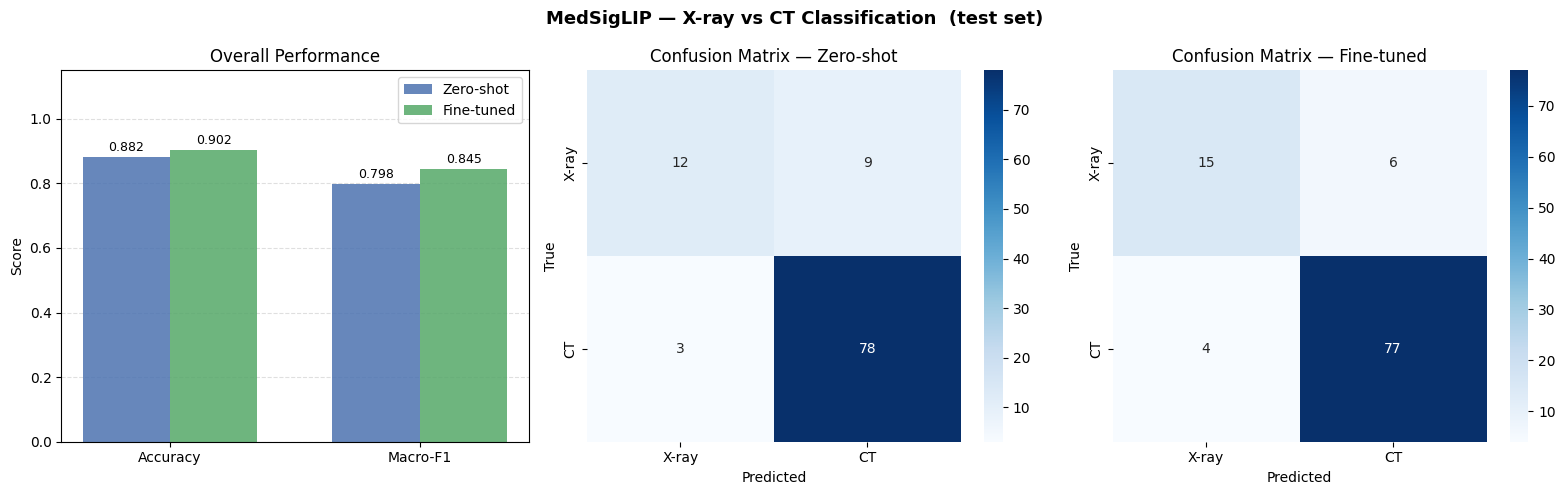

Saved classification_results.png


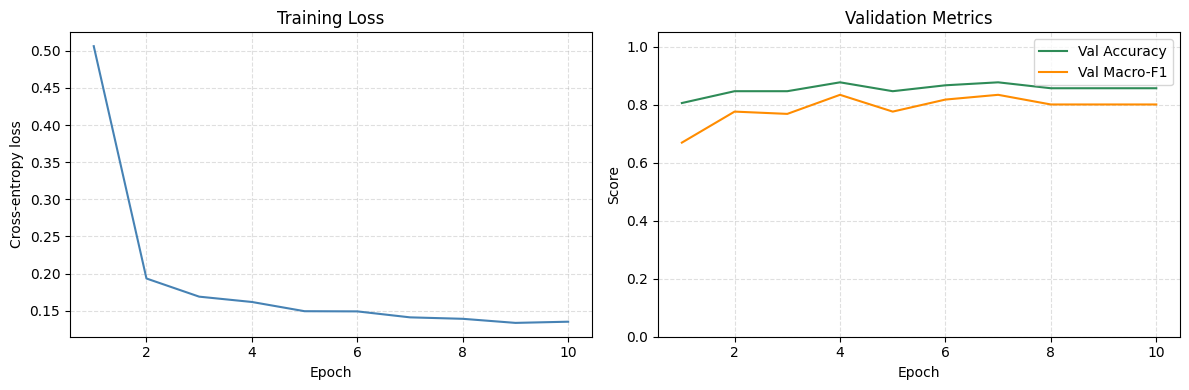

Saved classification_training_curve.png


In [ ]:
# MedSigLIP Classification: Results Visualisation

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle("MedSigLIP — X-ray vs CT Classification  (test set)",
             fontsize=13, fontweight="bold")

# Accuracy & F1 bar chart
ax = axes[0]
x = np.arange(2)
width = 0.35
bars_zs = ax.bar(x - width/2, [zs_acc, zs_f1], width,
                 label="Zero-shot", color="#4C72B0", alpha=0.85)
bars_ft = ax.bar(x + width/2, [ft_acc, ft_f1], width,
                 label="Fine-tuned", color="#55A868", alpha=0.85)
for bars in (bars_zs, bars_ft):
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f"{bar.get_height():.3f}", ha="center", va="bottom", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(["Accuracy", "Macro-F1"])
ax.set_ylim(0, 1.15); ax.set_ylabel("Score")
ax.set_title("Overall Performance")
ax.legend(); ax.yaxis.grid(True, linestyle="--", alpha=0.4); ax.set_axisbelow(True)

# Confusion matrix: zero-shot
for ax, preds, title in [(axes[1], zs_preds, "Zero-shot"),
                          (axes[2], ft_preds, "Fine-tuned")]:
    cm = confusion_matrix(test_labels, preds)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=[ID2LABEL[i] for i in range(NUM_CLASSES)],
                yticklabels=[ID2LABEL[i] for i in range(NUM_CLASSES)])
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.set_title(f"Confusion Matrix — {title}")

plt.tight_layout()
plt.savefig("classification_results.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved classification_results.png")

# Training curve
hist_df = pd.DataFrame(history)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(hist_df["epoch"], hist_df["loss"], color="steelblue", linewidth=1.5)
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Cross-entropy loss"); ax1.set_title("Training Loss")
ax1.grid(True, linestyle="--", alpha=0.4)

ax2.plot(hist_df["epoch"], hist_df["val_acc"],  label="Val Accuracy", color="seagreen")
ax2.plot(hist_df["epoch"], hist_df["val_f1"],   label="Val Macro-F1", color="darkorange")
ax2.set_xlabel("Epoch"); ax2.set_ylabel("Score"); ax2.set_title("Validation Metrics")
ax2.legend(); ax2.set_ylim(0, 1.05)
ax2.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig("classification_training_curve.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved classification_training_curve.png")

# Free GPU memory before BiomedCLIP experiments
del classifier, ms_model
import gc; gc.collect(); torch.cuda.empty_cache()


In [ ]:
print("Cross-model summary will appear at the end of the BiomedCLIP experiments cell.")

Cross-model summary will appear at the end of the BiomedCLIP experiments cell.


## Task 2 — BiomedCLIP: Radiology Caption Retrieval

### Model: `microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224`

BiomedCLIP is a **CLIP-based** model pre-trained on **15 million** biomedical image-caption
pairs sourced from PubMed Central figures (the PMC-15M dataset). It pairs a **ViT-B/16**
vision encoder with a **PubMedBERT** text encoder, both projecting into a shared
512-dimensional embedding space. We fine-tune it for image-to-text retrieval on our
OpenPMC radiology subset.

#### 📄 Papers & Resources

- **BiomedCLIP** — *"Large-Scale Domain-Specific Pretraining for Biomedical Vision-Language Processing"*, Zhang et al., 2023 — [arXiv:2303.00915](https://arxiv.org/abs/2303.00915)
- **CLIP (InfoNCE)** — *"Learning Transferable Visual Models From Natural Language Supervision"*, Radford et al., OpenAI 2021 — [arXiv:2103.00020](https://arxiv.org/abs/2103.00020)
- **PubMedBERT** — *"Domain-Specific Language Model Pretraining for Biomedical NLP"*, Gu et al., 2021 — [arXiv:2007.15779](https://arxiv.org/abs/2007.15779)
- **Model card**: [microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224](https://huggingface.co/microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224)

#### Architecture

```
Image (224×224) ──► ViT-B/16 ──► Linear projection ──► v ∈ ℝ^512  (L2-norm)
                                                              ↕ cosine similarity
Caption ─────────► PubMedBERT ──► Linear projection ──► u ∈ ℝ^512  (L2-norm)
```

BiomedCLIP was pre-trained on **PMC-15M** — 15 million biomedical figure-caption pairs —
which is approximately 10× larger than the training data for OpenAI's original CLIP in the
biomedical domain. PubMedBERT provides strong biomedical text representations through
domain-specific pre-training on PubMed abstracts and PMC full-text articles, making it
substantially more sensitive to clinical and radiological terminology than general-purpose
language encoders.

#### 📐 CLIP / InfoNCE Training Loss

CLIP is trained with a **symmetric cross-entropy loss** over pairwise cosine similarities
(the InfoNCE objective). Given a batch of $N$ matched image-text pairs, the scaled
pairwise similarity is:

$$S_{ij} = \frac{v_i \cdot u_j}{\|v_i\|\,\|u_j\|} \cdot e^{\log\tau}$$

where $\tau$ is a learnable temperature parameter (`model.logit_scale`). The symmetric loss is:

$$\mathcal{L}_{\text{CLIP}} = -\frac{1}{2N}\sum_{i=1}^{N}\left[\log\frac{e^{S_{ii}}}{\sum_{j=1}^{N} e^{S_{ij}}} + \log\frac{e^{S_{ii}}}{\sum_{j=1}^{N} e^{S_{ji}}}\right]$$

The first term is a $N$-class classification: *find the correct text among all $N$ texts given
image $i$*. The second term is the transpose: *find the correct image among all $N$ images
given text $i$*. The model is trained to push matched pairs to high similarity and all
mismatched pairs to low similarity simultaneously in both directions.

**InfoNCE / Memory Bank connection**: each row of $S$ is a $N$-class cross-entropy. The
`EmbeddingMemoryBank` used in this project appends 256 extra negative columns to each row,
expanding the denominator from $N$ to $N + 256$ without loading extra samples into GPU memory:

$$\mathcal{L}_{\text{+bank}} = -\frac{1}{N}\sum_{i=1}^{N}\log\frac{e^{S_{ii}}}{\sum_{j=1}^{N} e^{S_{ij}} + \sum_{k=1}^{K} e^{S_{ik}^{\text{bank}}}}$$

where $K = 256$ is the memory bank capacity and $S_{ik}^{\text{bank}}$ are similarities
against detached embeddings from previous batches.

#### Design Decisions (this project)

- **Vision encoder frozen** throughout; only the text encoder is fine-tuned
- **EmbeddingMemoryBank** (capacity = 256) — expands effective negatives from `batch_size − 1` to `batch_size + 255`
- **Gradient accumulation** (4 steps) — effective batch size of 32 while only 8 samples in GPU memory
- Evaluation via **FAISS `IndexFlatIP`** (exact cosine similarity) in both I2T and T2I directions


In [36]:
# BiomedCLIP: Zero-Shot Quickstart (adapted from HuggingFace model card)
# Demonstrates standard zero-shot usage of BiomedCLIP BEFORE any fine-tuning
# Source: https://huggingface.co/microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224

# Load model, transforms and tokenizer from HuggingFace Hub
model_bc, preprocess_val_bc = create_model_from_pretrained(
    'hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224'
)
tokenizer_bc = get_tokenizer(
    'hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224'
)
model_bc.eval()

# Pick a sample image and its caption from our collected dataset
sample_row = df.iloc[0]
image_bc = preprocess_val_bc(
    Image.open(sample_row["image_path"]).convert("RGB")
).unsqueeze(0)

# Candidate captions for zero-shot retrieval
# The true caption is included as one of the candidates, it should score highest
candidate_texts = [
    "chest x-ray showing normal lung fields",
    "CT scan of the abdomen and pelvis with contrast",
    "MRI of the brain showing white matter hyperintensities",
    "ultrasound of the liver with hepatic lesion",
    sample_row["caption"][:120], # the actual matching caption
]

texts_bc = tokenizer_bc(candidate_texts)

# Forward pass
with torch.no_grad():
    image_features = model_bc.encode_image(image_bc)
    text_features = model_bc.encode_text(texts_bc)

    # L2 normalise before cosine similarity
    image_features = image_features / image_features.norm(dim=-1, keepdim=True)
    text_features = text_features / text_features.norm(dim=-1, keepdim=True)

    # Softmax over cosine similarities (×100 for numerical stability)
    similarity = (100.0 * image_features @ text_features.T).softmax(dim=-1)

# Results
true_caption = sample_row['caption'][:120]
print(f"True label  : {sample_row['rad_submodality']}")
print(f"True caption: {true_caption[:80]}...\n")
print("Zero-shot retrieval scores (softmax over candidates):")
for text, score in zip(candidate_texts, similarity[0]):
    marker = "  ◄ TRUE CAPTION" if text == true_caption else ""
    bar = "█" * int(score.item() * 50)
    print(f"  {score:.4f}  {bar:50s}  {text[:60]}{marker}")


tokenizer_config.json:   0%|          | 0.00/28.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

True label  : ct
True caption: Chest CT of the patient in case 2 aged 10 yr and 1 mo....

Zero-shot retrieval scores (softmax over candidates):
  0.9588  ███████████████████████████████████████████████     chest x-ray showing normal lung fields
  0.0000                                                      CT scan of the abdomen and pelvis with contrast
  0.0003                                                      MRI of the brain showing white matter hyperintensities
  0.0000                                                      ultrasound of the liver with hepatic lesion
  0.0408  ██                                                  Chest CT of the patient in case 2 aged 10 yr and 1 mo.  ◄ TRUE CAPTION


In [35]:
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "open_clip_torch", "optuna"], check=True)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'open_clip_torch', 'optuna'], returncode=0)

In [ ]:
# BiomedCLIP RETRIEVAL EXPERIMENTS
#
# microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224
# CLIP-based (open_clip): softmax InfoNCE loss + EmbeddingMemoryBank
#
# Configurations:
# [0] Zero-shot — pre-trained weights, no fine-tuning
# [1] Fine-tuned — 5 epochs with CLIP loss + memory bank

device = "cuda" if torch.cuda.is_available() else "cpu"
bmc_name = "hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224"

# Evaluation corpus: all captions (train + val + test)
bmc_eval_corpus = (train_df["caption"].tolist() +
                   val_df["caption"].tolist()   +
                   test_df["caption"].tolist())

# Validation corpus during training (test held out for final evaluation)
bmc_val_corpus  = train_df["caption"].tolist() + val_df["caption"].tolist()

EPOCHS_BMC = 5
BS_BMC = 8 # effective batch = 8 × 4 accum_steps = 32 gradient updates/step
ACCUM_STEPS = 4 # gradient accumulation
MEMORY_BANK_DIM = 512 # BiomedCLIP projection dimension
MEMORY_BANK_CAP = 256 # circular buffer capacity


# Optuna hyperparameter search
def bmc_objective(trial):
    lr_trial = trial.suggest_float("lr", 1e-6, 5e-5, log=True)
    wd_trial = trial.suggest_float("weight_decay", 1e-5, 1e-2, log=True)
    wr_trial = trial.suggest_float("warmup_ratio", 0.0,  0.3)

    bmc_m, bmc_pre, bmc_tok = prepare_biomedclip(bmc_name, device)

    # Small memory bank for search trials (full capacity in final run)
    bank = EmbeddingMemoryBank(size=64, dim=MEMORY_BANK_DIM, device=device)

    def _fwd(paths, caps):
        return forward_batch_biomedclip(
            (bmc_m, bmc_pre, bmc_tok), paths, caps, device)

    def _loss(img, txt, memory_bank=None):
        return clip_loss(img, txt, memory_bank=memory_bank)

    _, val_mrr, _ = train_contrastive(
        "BiomedCLIP_search", bmc_m, (bmc_pre, bmc_tok),
        train_df, val_df,
        corpus_texts=bmc_val_corpus,
        forward_batch_fn=_fwd,
        loss_fn=_loss,
        epochs=2,
        lr=lr_trial,
        batch_size=BS_BMC,
        accumulation_steps=ACCUM_STEPS,
        weight_decay=wd_trial,
        warmup_ratio=wr_trial,
        memory_bank=bank,
        return_metrics=True,
    )
    del bmc_m; gc.collect(); torch.cuda.empty_cache()
    return val_mrr

print("Running Optuna search for BiomedCLIP hyperparameters ...")
bmc_study = optuna.create_study(direction="maximize",
                                 sampler=optuna.samplers.TPESampler(seed=42))
bmc_study.optimize(bmc_objective, n_trials=5, show_progress_bar=True)
best_bmc_params = bmc_study.best_params
print("Best BiomedCLIP params:", best_bmc_params)


# Helper: evaluate in both directions
def run_eval_bmc(bmc_model, bmc_pre, bmc_tok, label):
    bmc_model.eval()
    _txt = lambda t, batch_size=64: embed_texts_generic(
        t, (bmc_pre, bmc_tok), bmc_model, batch_size=batch_size)
    _img = lambda p, batch_size=16: embed_images_clip_like(
        p, (bmc_pre, bmc_tok), bmc_model, batch_size=batch_size)
    both = evaluate_retrieval_faiss(
        lambda t, batch_size=64: _txt(t, batch_size=batch_size),
        lambda p, batch_size=16: _img(p, batch_size=batch_size),
        query_df=test_df, corpus_texts=bmc_eval_corpus,
    )
    print(f"  {label}  I2T: {both['I2T']}  T2I: {both['T2I']}")
    return both


bmc_results = []


# [0] Zero-shot
print("\n[0] BiomedCLIP — Zero-shot")
bmc_m, bmc_pre, bmc_tok = prepare_biomedclip(bmc_name, device)
both = run_eval_bmc(bmc_m, bmc_pre, bmc_tok, "Zero-shot")
bmc_results.append({"model": "BiomedCLIP", "config": "Zero-shot",
                    **{"I2T_"+k: v for k, v in both["I2T"].items()},
                    **{"T2I_"+k: v for k, v in both["T2I"].items()}})


# [1] Fine-tuned with memory bank
print("\n[1] BiomedCLIP — Fine-tuning with EmbeddingMemoryBank")
bank = EmbeddingMemoryBank(size=MEMORY_BANK_CAP, dim=MEMORY_BANK_DIM, device=device)

def _fwd_bmc(paths, caps):
    return forward_batch_biomedclip((bmc_m, bmc_pre, bmc_tok), paths, caps, device)

def _loss_bmc(img, txt, memory_bank=None):
    return clip_loss(img, txt, memory_bank=memory_bank)

bmc_m.train()
bmc_m, bmc_history = train_contrastive(
    "BiomedCLIP_CLIP", bmc_m, (bmc_pre, bmc_tok),
    train_df, val_df,
    corpus_texts=bmc_val_corpus,
    forward_batch_fn=_fwd_bmc,
    loss_fn=_loss_bmc,
    epochs=EPOCHS_BMC,
    lr=best_bmc_params.get("lr", 1e-5),
    batch_size=BS_BMC,
    accumulation_steps=ACCUM_STEPS,
    weight_decay=best_bmc_params.get("weight_decay", 1e-3),
    warmup_ratio=best_bmc_params.get("warmup_ratio", 0.10),
    memory_bank=bank,
)
both = run_eval_bmc(bmc_m, bmc_pre, bmc_tok, "Fine-tuned + MemoryBank")
bmc_results.append({"model": "BiomedCLIP", "config": "Fine-tuned + MemoryBank",
                    **{"I2T_"+k: v for k, v in both["I2T"].items()},
                    **{"T2I_"+k: v for k, v in both["T2I"].items()}})
del bmc_m; gc.collect(); torch.cuda.empty_cache()

bmc_results_df = pd.DataFrame(bmc_results)
print("\nBiomedCLIP results:")
print(bmc_results_df.to_string(index=False))


[I 2026-03-17 18:57:45,887] A new study created in memory with name: no-name-b1ef56bd-1990-4231-a6d8-f25c542cb327


Running Optuna search for BiomedCLIP hyperparameters ...


  0%|          | 0/5 [00:00<?, ?it/s]

BiomedCLIP — trainable: 109,710,848 / 195,902,721  (vision frozen)

-----------------------------------------------------
Epoch 1/2
  step  epoch      loss   pos_sim   neg_sim       gap
-----------------------------------------------------


[BiomedCLIP_search] epoch 1:   0%|          | 0/100 [00:00<?, ?it/s]

...

[BiomedCLIP_CLIP] val I2T: {'R@1': 0.2959, 'R@5': 0.4694, 'R@10': 0.5918, 'MRR': 0.3893}
[BiomedCLIP_CLIP] Restored best checkpoint  (val MRR: 0.4012)


Embedding captions:   0%|          | 0/16 [00:00<?, ?it/s]

Embedding images:   0%|          | 0/7 [00:00<?, ?it/s]

Embedding captions:   0%|          | 0/2 [00:00<?, ?it/s]

  Fine-tuned + MemoryBank  I2T: {'R@1': 0.2843, 'R@5': 0.4902, 'R@10': 0.598, 'MRR': 0.377}  T2I: {'R@1': 0.5, 'R@5': 0.7745, 'R@10': 0.8529, 'MRR': 0.6076}

BiomedCLIP results:
     model                  config  I2T_R@1  I2T_R@5  I2T_R@10  I2T_MRR  T2I_R@1  T2I_R@5  T2I_R@10  T2I_MRR
BiomedCLIP               Zero-shot   0.2745   0.4314     0.549   0.3429   0.5196   0.7647    0.8529   0.6185
BiomedCLIP Fine-tuned + MemoryBank   0.2843   0.4902     0.598   0.3770   0.5000   0.7745    0.8529   0.6076


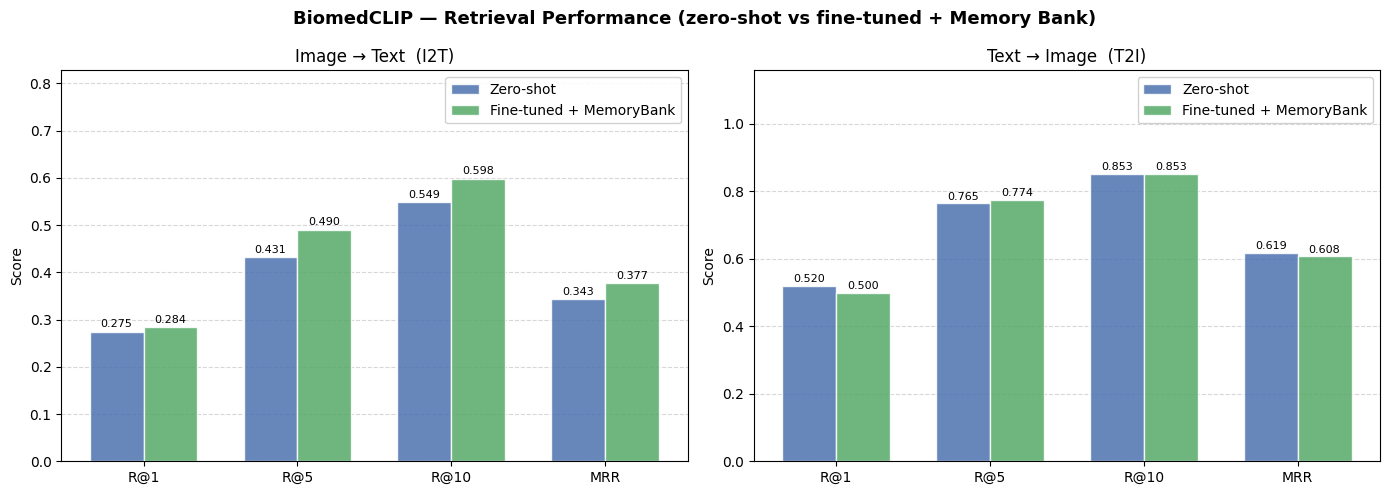

Saved biomedclip_results.png


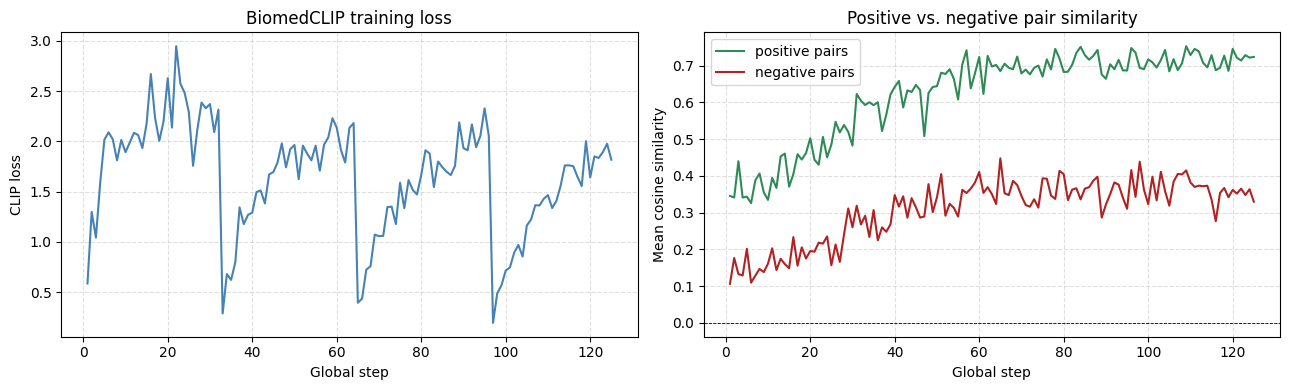

Saved biomedclip_training_curve.png


In [ ]:
metrics = ["R@1", "R@5", "R@10", "MRR"]
colors = {"Zero-shot": "#4C72B0", "Fine-tuned + MemoryBank": "#55A868"}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("BiomedCLIP — Retrieval Performance (zero-shot vs fine-tuned + Memory Bank)",
             fontsize=13, fontweight="bold")

x = np.arange(len(metrics))
width = 0.35

for ax_i, direction in enumerate(["I2T", "T2I"]):
    ax     = axes[ax_i]
    prefix = direction + "_"
    for i, (_, row) in enumerate(bmc_results_df.iterrows()):
        vals = [row[prefix + m] for m in metrics]
        col  = colors.get(row["config"], "grey")
        bars = ax.bar(x + (i - 0.5) * width, vals, width,
                      label=row["config"], color=col, alpha=0.85, edgecolor="white")
        for bar, v in zip(bars, vals):
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.005,
                    f"{v:.3f}", ha="center", va="bottom", fontsize=8)
    title_map = {"I2T": "Image → Text  (I2T)", "T2I": "Text → Image  (T2I)"}
    ax.set_xticks(x); ax.set_xticklabels(metrics)
    max_val = bmc_results_df[[prefix + m for m in metrics]].values.max()
    ax.set_ylim(0, max_val * 1.3 + 0.05)
    ax.set_ylabel("Score"); ax.set_title(title_map[direction])
    ax.legend(framealpha=0.9)
    ax.yaxis.grid(True, linestyle="--", alpha=0.5); ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("biomedclip_results.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved biomedclip_results.png")

# BiomedCLIP: positive vs negative similarity training curve
if bmc_history:
    hist_df = pd.DataFrame(bmc_history)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
    ax1.plot(hist_df["step"], hist_df["loss"], color="steelblue", linewidth=1.5)
    ax1.set_xlabel("Global step"); ax1.set_ylabel("CLIP loss")
    ax1.set_title("BiomedCLIP training loss")
    ax1.grid(True, linestyle="--", alpha=0.4)

    ax2.plot(hist_df["step"], hist_df["pos_sim"], label="positive pairs", color="seagreen")
    ax2.plot(hist_df["step"], hist_df["neg_sim"], label="negative pairs", color="firebrick")
    ax2.axhline(0, color="black", linewidth=0.6, linestyle="--")
    ax2.set_xlabel("Global step"); ax2.set_ylabel("Mean cosine similarity")
    ax2.set_title("Positive vs. negative pair similarity")
    ax2.legend(); ax2.grid(True, linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.savefig("biomedclip_training_curve.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved biomedclip_training_curve.png")


## Conclusion

This project used two pre-trained medical image-text encoders on the same radiology subset: **MedSigLIP** for supervised X-ray vs CT classification and **BiomedCLIP** for image↔caption retrieval. Both were compared zero-shot and fine-tuned. All numbers below are the test-set results printed by the cells above.

---

## Task 1 - MedSigLIP: Classification Results

### Experimental Results (test set, 102 images: 21 X-ray / 81 CT)

| Model | Accuracy | Macro-F1 | X-ray recall | CT recall |
|-------|----------|----------|--------------|-----------|
| Zero-shot (cosine similarity to class prompts) | 0.8824 | 0.7976 | 0.57 (12/21) | 0.96 (78/81) |
| **Fine-tuned head** | **0.9020** | **0.8445** | **0.71 (15/21)** | **0.95 (77/81)** |

### What changed with fine-tuning

The zero-shot model is biased toward CT, the majority class (79% of the test set): it recovers 96% of CT images but only 57% of X-rays. Training a small head on the frozen MedSigLIP image embeddings raises X-ray recall from 57% to 71% (three more X-rays found) at the cost of one CT image, lifting macro-F1 from 0.80 to 0.84. In absolute terms the fine-tuned model classifies **two more test images correctly** (92 vs 90 of 102). No class weighting or resampling was used; the gain comes from supervised training alone.

### Configuration actually used

| Item | Value |
|------|-------|
| Backbone | MedSigLIP ViT-L/14 (448 px); image embedding = `vision_model(...).pooler_output`, 1152-d, L2-normalised |
| Head | Linear(1152→256) → ReLU → Dropout(0.3) → Linear(256→2); 295,682 trainable parameters |
| Optimiser | AdamW over the **head parameters only**, lr 1e-3, weight decay 1e-4 |
| Schedule | 10 epochs, batch size 16, cosine decay with 10% linear warmup |
| Loss | Standard cross-entropy (no class weights) |
| Augmentation | None |
| Checkpoint | Best validation **accuracy** (0.8776, reached at epoch 4) |

Implementation note: the classifier wrapper marks the last two vision layers as trainable, but the optimiser is built from the head parameters only, so those layers are never updated. In practice the backbone is frozen and only the head is trained. The `Trainable: 480,509,588` line printed at the start of the experiment cell counts every parameter of the wrapped model that has `requires_grad` set, including the text tower, which is unused for classification.

### How stable was training?

Validation accuracy moved between 0.81 and 0.88 and validation macro-F1 between 0.67 and 0.83 across the ten epochs, on a validation set of 98 images. Checkpoint choice and the final test numbers should therefore be read as one run on a small split.

### Data ceiling

Only 21 test images are X-rays, so a single misclassified X-ray changes macro-F1 by roughly 0.02. The improvement over zero-shot (three X-rays) is within what a different split or seed could change. Labels also come from a caption regex rather than from radiologists, which adds label noise to both training and evaluation.

---

## Task 2 - BiomedCLIP: Retrieval Results

BiomedCLIP is fine-tuned for retrieval with the vision encoder frozen and the text tower trained (109.7M of 195.9M parameters). The loss is the symmetric CLIP/InfoNCE loss with a 256-entry `EmbeddingMemoryBank` of detached past embeddings as extra negatives (batch 8 × 4 accumulation steps = effective batch 32; the 5 Optuna trials used a smaller bank of 64). Learning rate, weight decay and warmup came from a 5-trial Optuna search of 2 epochs each on validation MRR (best: lr 2.6e-5, weight decay 4.3e-5, warmup 0.055). The final run trained for 5 epochs and restored the epoch with the best validation MRR (0.4012, epoch 4).

### Experimental Results (test set, 102 query images)

| Config | I2T R@1 | I2T R@5 | I2T R@10 | I2T MRR | T2I R@1 | T2I R@5 | T2I R@10 | T2I MRR |
|---|---|---|---|---|---|---|---|---|
| Zero-shot | 0.2745 | 0.4314 | 0.5490 | 0.3429 | 0.5196 | 0.7647 | 0.8529 | 0.6185 |
| Fine-tuned + memory bank | 0.2843 | 0.4902 | 0.5980 | 0.3770 | 0.5000 | 0.7745 | 0.8529 | 0.6076 |

Image→text retrieval improves modestly: MRR +0.034 and R@5 +6 percentage points (six more queries with the right caption in the top five), while R@1 changes by a single query (28 → 29 of 102). Text→image is essentially unchanged. With 102 queries these differences are small relative to sampling noise, so the honest summary is "a modest I2T gain, no T2I gain".

### Evaluation set-up

- **I2T** ranks each test image against a pool of 1,000 captions (train + validation + test). Because the fine-tuned model was trained on 898 of those captions, the pool is slightly easier for it than for the zero-shot model.
- **T2I** ranks each test caption against the 102 test images only, so it is an easier task than I2T and the two directions are not directly comparable.

---

## Implementation Notes

| Note | Detail |
|---|---|
| Image embeddings (MedSigLIP) | Taken from `vision_model(...).pooler_output`; head input size from `config.vision_config.hidden_size` (1152) |
| Memory bank | Updated after the optimiser step with detached embeddings, so no gradient graph is retained |
| Data loading | Classification DataLoaders use `num_workers=2`; in Colab this printed harmless worker-shutdown messages at the end of each epoch, which have been removed from the saved output |
| Preprocessing | Images were saved after the official TF bilinear resize to 448×448 (MedSigLIP's pipeline); BiomedCLIP applies its own 224 px preprocessing |

---

## Limitations

- **Small test set** (102 images, 21 X-rays): results are single-run point estimates without confidence intervals.
- **Weak labels**: X-ray/CT labels derive from caption keywords, not expert annotation.
- **Single split, single seed**; no repeated runs.
- **Small tuning budget** for BiomedCLIP (5 Optuna trials of 2 epochs); the MedSigLIP head was not tuned.
- **Retrieval pool**: I2T and T2I use different candidate sets, and the I2T pool includes captions seen in fine-tuning.
